In [1]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, pearsonr
from scipy.optimize import minimize
from sklearn.model_selection import LeaveOneOut
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED)  # sklearn wants a RandomState

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



EXPLORATORY DATA ANALYSIS
n_samples=27, n_dims=5
Input min per dim : [0.    0.095 0.017 0.046 0.   ]
Input max per dim : [0.958 0.932 1.    1.    0.893]
y range: [-2.5712, -0.4525]  (best so far: idx 26, x*=[0.529 0.341 0.513 0.712 0.182])

Pearson correlation of each input with y (screening only):
  x1: r = +0.127
  x2: r = -0.518
  x3: r = +0.307
  x4: r = +0.519
  x5: r = -0.645


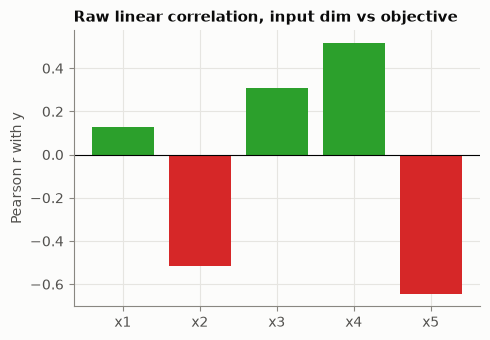

In [ ]:
# ---------------------------------------------------------------------------
# 1. DATA
# ---------------------------------------------------------------------------
X = np.load('..\Function_6_Data\Week_8_Data/F6_Week_8_inputs.npy')
y = np.load('..\Function_6_Data\Week_8_Data/F6_Week_8_outputs.npy')

n, d = X.shape
DIM_NAMES = [f"x{i+1}" for i in range(d)]
BOUNDS = [(0.0, 1.0)] * d  # confirmed empirically below

print("=" * 100)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 100)
print(f"n_samples={n}, n_dims={d}")
print("Input min per dim :", X.min(axis=0).round(3))
print("Input max per dim :", X.max(axis=0).round(3))
print(f"y range: [{y.min():.4f}, {y.max():.4f}]  (best so far: idx {y.argmax()}, "
      f"x*={X[y.argmax()].round(3)})")

# correlation of each input dimension with the output (screening only)
corrs = [pearsonr(X[:, k], y)[0] for k in range(d)]
print("\nPearson correlation of each input with y (screening only):")
for k in range(d):
    print(f"  {DIM_NAMES[k]}: r = {corrs[k]:+.3f}")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(DIM_NAMES, corrs, color=["#d62728" if c < 0 else "#2ca02c" for c in corrs])
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Pearson r with y")
ax.set_title("Raw linear correlation, input dim vs objective")
fig.tight_layout()


DATA TRANSFORMATION

Inputs : already confined to [0, 1]^5 (min=0 / max=1 are actually attained
         in the data), so no rescaling is applied.

Outputs: standardised to zero mean / unit variance (z = (y - mean) / std).



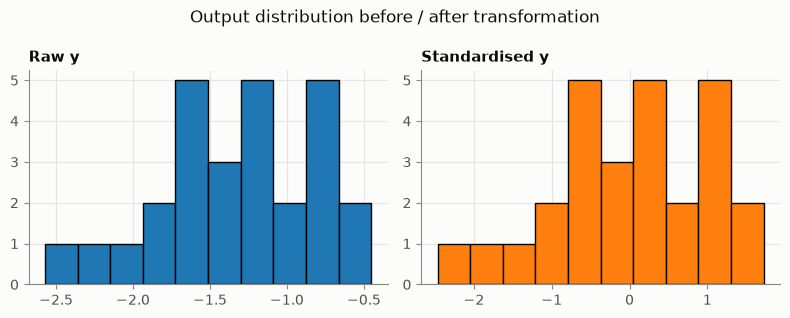

In [ ]:
# ---------------------------------------------------------------------------
# 2. DATA TRANSFORMATION
# ---------------------------------------------------------------------------
print("=" * 100)
print("DATA TRANSFORMATION")
print("=" * 100)
print("""
Inputs : already confined to [0, 1]^5.

Outputs: standardised to zero mean / unit variance (z = (y - mean) / std).
""")

y_mean, y_std = y.mean(), y.std()
y_z = (y - y_mean) / y_std

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
axes[0].hist(y, bins=10, color="#1f77b4", edgecolor="k")
axes[0].set_title("Raw y")
axes[1].hist(y_z, bins=10, color="#ff7f0e", edgecolor="k")
axes[1].set_title("Standardised y")
fig.suptitle("Output distribution before / after transformation")
fig.tight_layout()

SURROGATE MODEL SELECTION (ARD vs isotropic)
LOO total log predictive density - isotropic :  -35.490
LOO total log predictive density - ARD        :  -53.263
-> isotropic generalises better on held-out points; using it below.

Final kernel used for the acquisition step (fitted hyper-parameters):
  1.27**2 * Matern(length_scale=0.798, nu=2.5) + WhiteKernel(noise_level=0.000272)

Diagnostic ARD length-scales fit on ALL data (for interpretation
only - SHORTER length-scale = objective changes faster along that
axis = more relevant):
  x1: length_scale = 0.785
  x2: length_scale = 0.698
  x3: length_scale = 0.996
  x4: length_scale = 0.963
  x5: length_scale = 1.860


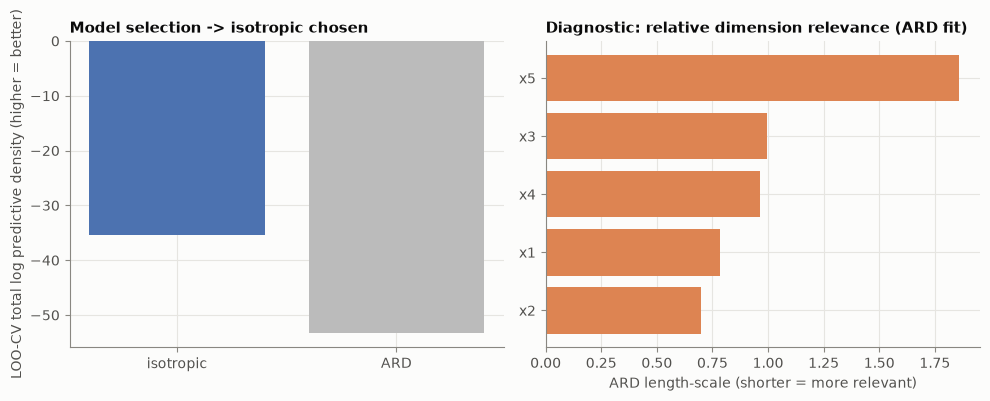

In [4]:
# ---------------------------------------------------------------------------
# 3. SURROGATE MODEL: GP, ARD vs ISOTROPIC (model-selected via LOO-CV)
# ---------------------------------------------------------------------------
print("=" * 100)
print("SURROGATE MODEL SELECTION (ARD vs isotropic)")
print("=" * 100)


def make_kernel(ard: bool):
    length_scale = np.ones(d) if ard else 1.0
    return (
        ConstantKernel(1.0, (1e-2, 1e2))
        * Matern(length_scale=length_scale, length_scale_bounds=(1e-2, 1e1), nu=2.5)
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-5, 1e0))
    )


def fit_gp(X_train, y_train, ard: bool, n_restarts=20):
    gp = GaussianProcessRegressor(
        kernel=make_kernel(ard),
        n_restarts_optimizer=n_restarts,
        normalize_y=False,     # already standardised y
        alpha=1e-10,           # numerical jitter only; WhiteKernel handles real noise
        random_state=SEED,
    )
    gp.fit(X_train, y_train)
    return gp


def loo_log_predictive_density(X, y, ard: bool):
    """Leave-one-out cross-validated predictive log-likelihood.
    """
    total = 0.0
    per_point = np.zeros(len(y))
    for i in range(len(y)):
        X_tr, y_tr = np.delete(X, i, axis=0), np.delete(y, i)
        gp = fit_gp(X_tr, y_tr, ard=ard, n_restarts=5)
        mu, sigma = gp.predict(X[i:i + 1], return_std=True)
        sigma = max(sigma[0], 1e-6)
        lp = norm.logpdf(y[i], loc=mu[0], scale=sigma)
        total += lp
        per_point[i] = lp
    return total, per_point


loo_iso, _ = loo_log_predictive_density(X, y_z, ard=False)
loo_ard, _ = loo_log_predictive_density(X, y_z, ard=True)
print(f"LOO total log predictive density - isotropic : {loo_iso:8.3f}")
print(f"LOO total log predictive density - ARD        : {loo_ard:8.3f}")
winner = "ARD" if loo_ard > loo_iso else "isotropic"
print(f"-> {winner} generalises better on held-out points; using it below.\n")

use_ard = loo_ard > loo_iso
gp_final = fit_gp(X, y_z, ard=use_ard, n_restarts=30)
print("Final kernel used for the acquisition step (fitted hyper-parameters):")
print(" ", gp_final.kernel_)

# Fit a *diagnostic* ARD model on the full data to visualise relative dimension importance.
gp_ard_diag = fit_gp(X, y_z, ard=True, n_restarts=30)
length_scales = gp_ard_diag.kernel_.k1.k2.length_scale
print("\nDiagnostic ARD length-scales fit on ALL data (for interpretation")
print("only - SHORTER length-scale = objective changes faster along that")
print("axis = more relevant):")
for name, ls in zip(DIM_NAMES, length_scales):
    print(f"  {name}: length_scale = {ls:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(["isotropic", "ARD"], [loo_iso, loo_ard],
            color=["#4c72b0" if not use_ard else "#bbbbbb",
                   "#4c72b0" if use_ard else "#bbbbbb"])
axes[0].set_ylabel("LOO-CV total log predictive density (higher = better)")
axes[0].set_title(f"Model selection -> {winner} chosen")
order = np.argsort(length_scales)
axes[1].barh([DIM_NAMES[k] for k in order], length_scales[order], color="#dd8452")
axes[1].set_xlabel("ARD length-scale (shorter = more relevant)")
axes[1].set_title("Diagnostic: relative dimension relevance (ARD fit)")
fig.tight_layout()



In [5]:
# ---------------------------------------------------------------------------
# 4. ACQUISITION FUNCTIONS
# ---------------------------------------------------------------------------
print("=" * 100)
print("ACQUISITION FUNCTION")
print("=" * 100)
print("""
Primary choice: Expected Improvement (EI), maximisation form:
    Z  = (mu(x) - f_best - xi) / sigma(x)
    EI(x) = (mu(x) - f_best - xi) * Phi(Z) + sigma(x) * phi(Z)      if sigma>0
          = 0                                                       if sigma=0
Why EI:
  - closed form, cheap and smooth (good gradients for L-BFGS-B)
  - naturally trades off exploitation (mu - f_best term) against
    exploration (sigma term), with a single, interpretable knob (xi)
  - well-suited to small, expensive-to-evaluate black boxes like this one
xi = 0.01 (small positive jitter).

Cross-check: Upper Confidence Bound (UCB), UCB(x) = mu(x) + kappa*sigma(x),
kappa = 2.0 (~95% confidence-style exploration bonus). If EI's and UCB's
optimum roughly agree, that increases confidence in the recommended point.
""")

f_best_z = y_z.max()  # incumbent best, standardised units
XI = 0.01
KAPPA = 2.0


def expected_improvement(Xq, gp, f_best, xi=XI):
    Xq = np.atleast_2d(Xq)
    mu, sigma = gp.predict(Xq, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    z = (mu - f_best - xi) / sigma
    ei = (mu - f_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei


def upper_confidence_bound(Xq, gp, kappa=KAPPA):
    Xq = np.atleast_2d(Xq)
    mu, sigma = gp.predict(Xq, return_std=True)
    return mu + kappa * sigma


def optimise_acquisition(neg_acq_fn, bounds, n_restarts=64):
    """Multi-start L-BFGS-B: acquisition."""
    dim = len(bounds)
    starts = rng.uniform([b[0] for b in bounds], [b[1] for b in bounds],
                          size=(n_restarts, dim))
    best_x, best_val = None, -np.inf
    for x0 in starts:
        res = minimize(neg_acq_fn, x0=x0, method="L-BFGS-B", bounds=bounds)
        val = -float(res.fun)
        if val > best_val:
            best_val, best_x = val, res.x
    return np.clip(best_x, 0.0, 1.0), best_val


x_next_ei, ei_val = optimise_acquisition(
    lambda x: -expected_improvement(x.reshape(1, -1), gp_final, f_best_z)[0], BOUNDS)
x_next_ucb, ucb_val = optimise_acquisition(
    lambda x: -upper_confidence_bound(x.reshape(1, -1), gp_final, KAPPA)[0], BOUNDS)

mu_ei_z, sig_ei_z = gp_final.predict(x_next_ei.reshape(1, -1), return_std=True)
mu_ei_raw = mu_ei_z[0] * y_std + y_mean
sig_ei_raw = sig_ei_z[0] * y_std

print(f"Current incumbent best (raw y): {y.max():.6f} at x={X[y.argmax()].round(6)}")
print(f"\n[EI]  next query point : {x_next_ei.round(6)}")
print(f"      EI value (standardised units): {ei_val:.6f}")
print(f"      GP predicted y at this point : {mu_ei_raw:.6f} +/- {2*sig_ei_raw:.6f} (95% band)")
print(f"\n[UCB] next query point : {x_next_ucb.round(6)}  (kappa={KAPPA}, cross-check only)")
print(f"      distance between EI's and UCB's suggestions: "
      f"{np.linalg.norm(x_next_ei - x_next_ucb):.6f}")



ACQUISITION FUNCTION

Primary choice: Expected Improvement (EI), maximisation form:
    Z  = (mu(x) - f_best - xi) / sigma(x)
    EI(x) = (mu(x) - f_best - xi) * Phi(Z) + sigma(x) * phi(Z)      if sigma>0
          = 0                                                       if sigma=0
Why EI:
  - closed form, cheap and smooth (good gradients for L-BFGS-B)
  - naturally trades off exploitation (mu - f_best term) against
    exploration (sigma term), with a single, interpretable knob (xi)
  - well-suited to small, expensive-to-evaluate black boxes like this one
xi = 0.01 (small positive jitter).

Cross-check: Upper Confidence Bound (UCB), UCB(x) = mu(x) + kappa*sigma(x),
kappa = 2.0 (~95% confidence-style exploration bonus). If EI's and UCB's
optimum roughly agree, that increases confidence in the recommended point.

Current incumbent best (raw y): -0.452488 at x=[0.528981 0.34102  0.512747 0.711962 0.181667]

[EI]  next query point : [0.434228 0.45397  0.417472 0.730647 0.125786]
      EI

PLOTS

RECOMMENDED NEXT QUERY POINT (Expected Improvement):
  x_next = [0.4342, 0.454, 0.4175, 0.7306, 0.1258]




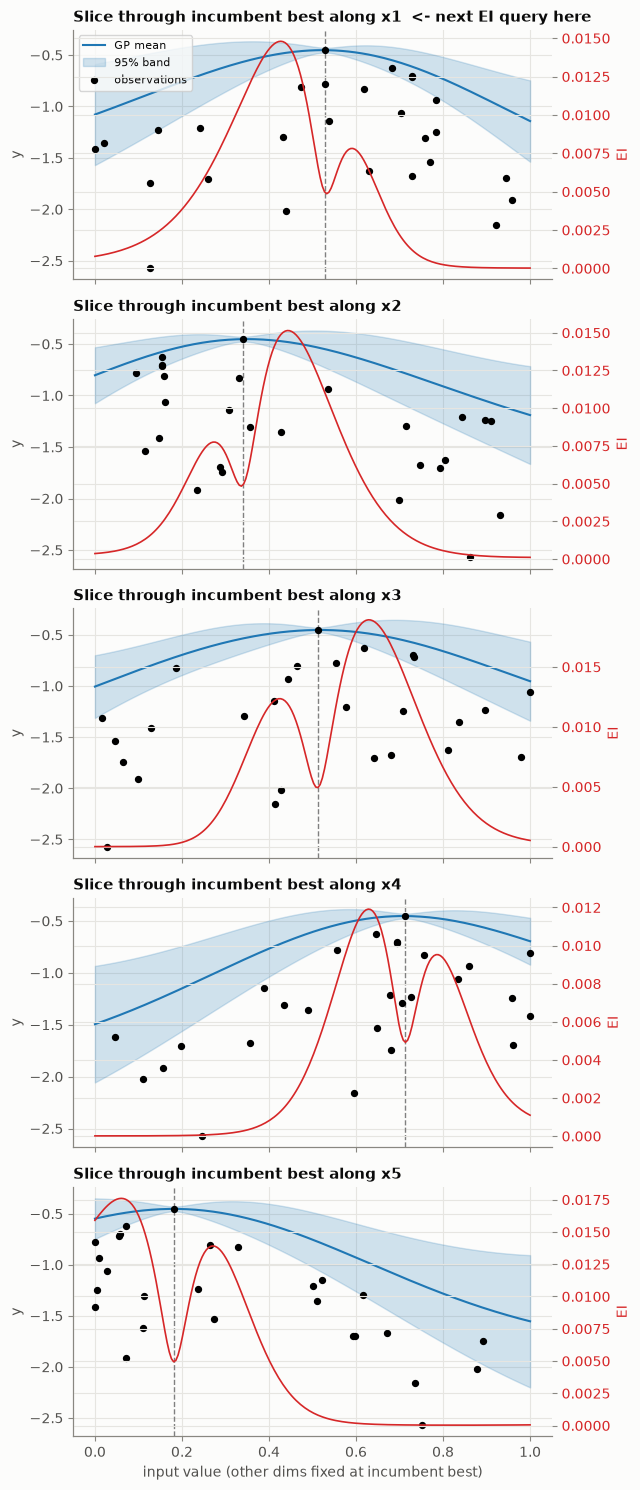

In [6]:
# ---------------------------------------------------------------------------
# PLOTS: 1-D slices through the best point + convergence
# ---------------------------------------------------------------------------
print("=" * 100)
print("PLOTS")
print("=" * 100)

x_star = X[y.argmax()].copy()  # current best observed point, used as the
                               # "anchor" for 1-D slice plots (all other
                               # dims held fixed at this incumbent)
grid = np.linspace(0, 1, 200)

print("\nRECOMMENDED NEXT QUERY POINT (Expected Improvement):")
print("  x_next =", np.round(x_next_ei, 4).tolist())
print('\n')
fig, axes = plt.subplots(d, 1, figsize=(6.5, 3 * d), sharex=True)
for k in range(d):
    Xg = np.tile(x_star, (len(grid), 1))
    Xg[:, k] = grid
    mu_z, sig_z = gp_final.predict(Xg, return_std=True)
    mu_raw = mu_z * y_std + y_mean
    sig_raw = sig_z * y_std
    ei_curve = expected_improvement(Xg, gp_final, f_best_z)

    ax = axes[k]
    ax.plot(grid, mu_raw, color="#1f77b4", label="GP mean")
    ax.fill_between(grid, mu_raw - 2 * sig_raw, mu_raw + 2 * sig_raw,
                     color="#1f77b4", alpha=0.2, label="95% band")
    ax.scatter(X[:, k], y, color="k", s=18, zorder=5, label="observations")
    ax.axvline(x_star[k], color="gray", ls="--", lw=1)

    ax2 = ax.twinx()
    ax2.plot(grid, ei_curve, color="#d62728", lw=1.2, label="EI")
    ax2.set_ylabel("EI", color="#d62728")
    ax2.tick_params(axis="y", labelcolor="#d62728")

    ax.set_ylabel("y")
    ax.set_title(f"Slice through incumbent best along {DIM_NAMES[k]}"
                 f"{'  <- next EI query here' if k == 0 else ''}")
    if k == 0:
        ax.legend(loc="upper left", fontsize=8)

axes[-1].set_xlabel("input value (other dims fixed at incumbent best)")
fig.tight_layout()

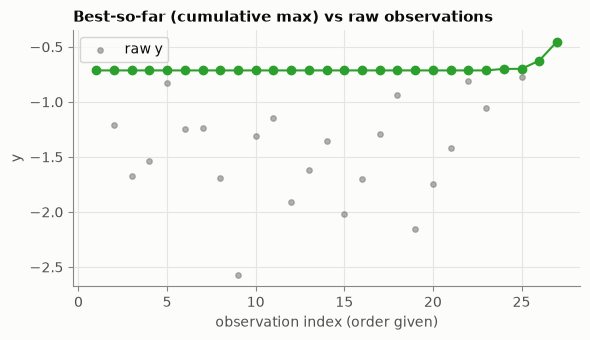

In [7]:
# convergence: best-so-far as points were observed, in the given order
best_so_far = np.maximum.accumulate(y)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, n + 1), best_so_far, marker="o", color="#2ca02c")
ax.scatter(range(1, n + 1), y, color="gray", s=15, alpha=0.6, label="raw y")
ax.set_xlabel("observation index (order given)")
ax.set_ylabel("y")
ax.set_title("Best-so-far (cumulative max) vs raw observations")
ax.legend()
fig.tight_layout()